In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [115]:
df=pd.read_csv('data.csv')
df=pd.DataFrame(df)

In [116]:
df.head()

,Price,Status,Area,Rate per sqft,Property Type,Locality,Builder Name,RERA Approval,BHK_Count,Socity,Company Name,Flat Type
0,10700000,Under Construction,1138,"9,450",2 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,home,Approved by RERA,2,M3M Antalya Hills Phase I,M3M,Apartment
1,14400000,Under Construction,1528,"9,450",3 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,Property In Gurgaon,Approved by RERA,3,M3M Antalya Hills Phase I,M3M,Apartment
2,10700000,Under Construction,1138,"9,450",2 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,properties for sale in Gurgaon,Approved by RERA,2,M3M Antalya Hills Phase I,M3M,Apartment
3,40000000,Ready to move,4500,"8,888",4 BHK Independent Floor,Sector 57,MM India Pvt Ltd,Not approved by RERA,4,Outside Socity,Outside,Plot
4,24000000,Under Construction,1800,"13,333",3 BHK Independent Floor in Anant Raj Estate Plots,Sector 63,MM India Pvt Ltd,Approved by RERA,3,Anant Raj Estate Plots,Anant,Floor


In [117]:
df.columns=df.columns.str.strip().str.lower().str.replace(' ','_')

In [118]:
df=df.drop_duplicates()

In [119]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14223 entries, 0 to 19514
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   price          14223 non-null  object
 1   status         14223 non-null  object
 2   area           14223 non-null  int64 
 3   rate_per_sqft  14223 non-null  object
 4   property_type  14223 non-null  object
 5   locality       14223 non-null  object
 6   builder_name   14223 non-null  object
 7   rera_approval  14223 non-null  object
 8   bhk_count      14223 non-null  int64 
 9   socity         14223 non-null  object
 10  company_name   14223 non-null  object
 11  flat_type      14223 non-null  object
dtypes: int64(2), object(10)
memory usage: 1.4+ MB


Numeric columns set data type

In [120]:
df['price']=df['price'].astype(str).str.replace(",","").astype(float)
df['area']=df['area'].astype(str).str.replace(",","").astype(int)
df['rate_per_sqft']=df['rate_per_sqft'].astype(str).str.replace(",","").astype(int)

In [121]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14223 entries, 0 to 19514
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          14223 non-null  float64
 1   status         14223 non-null  object 
 2   area           14223 non-null  int64  
 3   rate_per_sqft  14223 non-null  int64  
 4   property_type  14223 non-null  object 
 5   locality       14223 non-null  object 
 6   builder_name   14223 non-null  object 
 7   rera_approval  14223 non-null  object 
 8   bhk_count      14223 non-null  int64  
 9   socity         14223 non-null  object 
 10  company_name   14223 non-null  object 
 11  flat_type      14223 non-null  object 
dtypes: float64(1), int64(3), object(8)
memory usage: 1.4+ MB


Catogarial columns cleaning

In [122]:
df['status']=df['status'].str.strip().str.lower()
df['rera_approval']=df['rera_approval'].str.strip().str.lower().map({'approved by rera':True,'not approved by rera':False})
df['flat_type']=df['flat_type'].str.strip().str.lower()

In [123]:
df=df.drop_duplicates()

In [124]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14223 entries, 0 to 19514
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          14223 non-null  float64
 1   status         14223 non-null  object 
 2   area           14223 non-null  int64  
 3   rate_per_sqft  14223 non-null  int64  
 4   property_type  14223 non-null  object 
 5   locality       14223 non-null  object 
 6   builder_name   14223 non-null  object 
 7   rera_approval  14223 non-null  bool   
 8   bhk_count      14223 non-null  int64  
 9   socity         14223 non-null  object 
 10  company_name   14223 non-null  object 
 11  flat_type      14223 non-null  object 
dtypes: bool(1), float64(1), int64(3), object(7)
memory usage: 1.3+ MB


Which is the costest falt in data base

In [125]:
costest_flat=df.loc[df['price'].idxmax()]

In [126]:
costest_flat

price                                1226300000.0
status                              ready to move
area                                        16500
rate_per_sqft                               74323
property_type    6 BHK Apartment in DLF Camellias
locality                                Sector 42
builder_name                    Provident Capital
rera_approval                               False
bhk_count                                       6
socity                              DLF Camellias
company_name                                  DLF
flat_type                               apartment
Name: 2839, dtype: object

In [127]:
row = costest_flat

print(
    f"This is a {row['bhk_count']} BHK {row['flat_type']} in {row['socity']}, "
    f"{row['locality']}, built by {row['company_name']} (builder: {row['builder_name']}). "
    f"It has an area of {row['area']} sq ft at ₹{row['rate_per_sqft']:,} per sq ft, "
    f"priced at ₹{row['price']/1e7:.2f} crore. "
    f"The property is {row['status']} and {'is' if row['rera_approval'] else 'is not'} RERA approved."
)

This is a 6 BHK apartment in  DLF Camellias, Sector 42, built by DLF (builder: Provident Capital). It has an area of 16500 sq ft at ₹74,323 per sq ft, priced at ₹122.63 crore. The property is ready to move and is not RERA approved.


In [128]:
df.groupby('locality')['price'].mean().idxmax()

'Baliawas'

In [129]:
highest_avg_locality=df.groupby('locality')['price'].mean().idxmax()

In [130]:
print(f"The locality with the highest price is: {highest_avg_locality}")

The locality with the highest price is: Baliawas


Q3.Which locality has the highest rate per square foot?

In [131]:
highest_rate_per_sqft=df.groupby('locality')['rate_per_sqft'].mean().idxmax()

In [132]:
print(f'The locality with the highest rate per sqft is: {highest_rate_per_sqft} ')

The locality with the highest rate per sqft is: Sector 42 


Q4.Do ready-to-move properties cost more than under-construction properties?

In [133]:
df.head()

,price,status,area,rate_per_sqft,property_type,locality,builder_name,rera_approval,bhk_count,socity,company_name,flat_type
0,10700000.0,under construction,1138,9450,2 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,home,True,2,M3M Antalya Hills Phase I,M3M,apartment
1,14400000.0,under construction,1528,9450,3 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,Property In Gurgaon,True,3,M3M Antalya Hills Phase I,M3M,apartment
2,10700000.0,under construction,1138,9450,2 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,properties for sale in Gurgaon,True,2,M3M Antalya Hills Phase I,M3M,apartment
3,40000000.0,ready to move,4500,8888,4 BHK Independent Floor,Sector 57,MM India Pvt Ltd,False,4,Outside Socity,Outside,plot
4,24000000.0,under construction,1800,13333,3 BHK Independent Floor in Anant Raj Estate Plots,Sector 63,MM India Pvt Ltd,True,3,Anant Raj Estate Plots,Anant,floor


In [134]:
ready_to_move_avg_price=df[df['status']=='ready to move']['price'].mean()
under_construction_avg_price=df[df['status']=='under construction']['price'].mean()
if under_construction_avg_price>ready_to_move_avg_price:
    print("Under-construction properties cost more on average then ready to move")
else:
    print("Ready-to-move properties cost more on average then under construction properties")

Ready-to-move properties cost more on average then under construction properties


Q5 Do Rera_approved properties command a price premium?

In [135]:
rera_approved_avg_price=df[df['rera_approval']==True]['price'].mean()
rera_not_approved_avg_price=df[df['rera_approval']==False]['price'].mean()
if ready_to_move_avg_price>rera_not_approved_avg_price:
    print(f'RERA-approved properties command a price premium')
else:
    print(f'RERA approved properties do not command a price premium')

RERA-approved properties command a price premium


Q6 How does area impact price

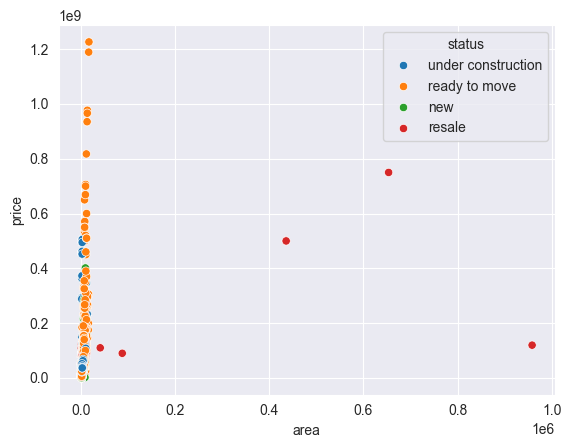

In [136]:
sns.scatterplot(data=df, x='area',y='price',hue='status')
plt.show()

Q7 Which BHK configration is most expensive?

In [137]:
df.head()

,price,status,area,rate_per_sqft,property_type,locality,builder_name,rera_approval,bhk_count,socity,company_name,flat_type
0,10700000.0,under construction,1138,9450,2 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,home,True,2,M3M Antalya Hills Phase I,M3M,apartment
1,14400000.0,under construction,1528,9450,3 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,Property In Gurgaon,True,3,M3M Antalya Hills Phase I,M3M,apartment
2,10700000.0,under construction,1138,9450,2 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,properties for sale in Gurgaon,True,2,M3M Antalya Hills Phase I,M3M,apartment
3,40000000.0,ready to move,4500,8888,4 BHK Independent Floor,Sector 57,MM India Pvt Ltd,False,4,Outside Socity,Outside,plot
4,24000000.0,under construction,1800,13333,3 BHK Independent Floor in Anant Raj Estate Plots,Sector 63,MM India Pvt Ltd,True,3,Anant Raj Estate Plots,Anant,floor


In [138]:
most_expensive_bhk=df.groupby('bhk_count')['rate_per_sqft'].mean().idxmax()

In [139]:
print(f"The most expensive BHK is {most_expensive_bhk}")

The most expensive BHK is 114


Q8 Which property type is the costliest?

In [140]:
print(df.groupby('company_name')['rate_per_sqft'].mean().sort_values(ascending=False).head(5))

company_name
Camelliaass    44724.333333
Cameliaas      40000.000000
Tulip          28571.121495
Prom           27358.600000
Magnoliaass    26666.000000
Name: rate_per_sqft, dtype: float64


Q10 Are larger home more expensive per sqft?

<Axes: xlabel='area', ylabel='rate_per_sqft'>

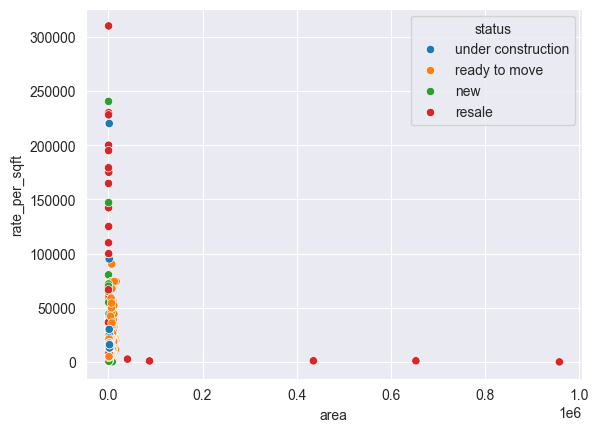

In [141]:
sns.scatterplot(data=df, x='area',y='rate_per_sqft',hue='status')